# ChromBPNet model performance — Figure 5b

This notebook summarizes ChromBPNet **peak count Pearson correlation** across cross-validation folds and reproduces the Figure 5b model-performance panel.

It expects the ChromBPNet output directory to contain sample directories with the structure:

```text
MODEL_ROOT/
├── sample_1/
│   ├── fold_0/evaluation/chrombpnet_metrics.json
│   ├── fold_1/evaluation/chrombpnet_metrics.json
│   └── ...
├── sample_2/
│   └── ...
```

For the representative predicted-versus-observed scatter panel, ChromBPNet's
`chrombpnet_only_peaks.counts_pearsonr.png` is read directly from the selected sample/fold evaluation directory.

**Before running:** edit only `MODEL_ROOT` below if needed.


In [4]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "axes.linewidth": 0.7,
})

# ------------------------------------------------------------------
# User setting
# ------------------------------------------------------------------
MODEL_ROOT = Path("/path/to/chrombpnet_model_selected_bias")

# Output directory for tables and Figure 5b panels
OUTPUT_DIR = Path("fig5b_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Representative model shown in the right-hand scatter panel
SCATTER_SAMPLE = "MEF_ATAC_mm10_Train_0.5"
SCATTER_FOLD = "fold_0"


## 1. Collect fold-level ChromBPNet evaluation metrics

In [14]:
metrics_files = sorted(
    MODEL_ROOT.glob("*/fold_*/evaluation/chrombpnet_metrics.json")
)

if not metrics_files:
    raise FileNotFoundError(
        f"No chrombpnet_metrics.json files found under: {MODEL_ROOT}"
    )

print(f"Found {len(metrics_files)} fold-level metric files.")



Found 100 fold-level metric files.


In [6]:
def flatten_json(obj, prefix=""):
    """Flatten nested dictionaries/lists into dot-delimited keys."""
    out = {}

    if isinstance(obj, dict):
        for key, value in obj.items():
            new_key = f"{prefix}.{key}" if prefix else str(key)
            out.update(flatten_json(value, new_key))

    elif isinstance(obj, list):
        for i, value in enumerate(obj):
            new_key = f"{prefix}.{i}" if prefix else str(i)
            out.update(flatten_json(value, new_key))

    else:
        out[prefix] = obj

    return out


def get_peak_count_pearson(metrics_json):
    """Return the peak-count Pearson metric from a ChromBPNet metrics JSON."""
    with open(metrics_json) as handle:
        metrics = json.load(handle)

    flat = flatten_json(metrics)
    candidates = []

    for key, value in flat.items():
        if not isinstance(value, (int, float)):
            continue

        key_lower = key.lower()

        if (
            "pearson" in key_lower
            and "peak" in key_lower
            and "count" in key_lower
            and "profile" not in key_lower
        ):
            candidates.append((key, float(value)))

    if not candidates:
        raise ValueError(
            f"No peak-count Pearson metric found in {metrics_json}"
        )

    # Preserve the behavior used in the original analysis:
    # if multiple matching keys exist, use the shortest matching key.
    candidates.sort(key=lambda x: len(x[0]))
    return candidates[0]


In [7]:
rows = []

for metrics_file in metrics_files:
    sample = metrics_file.parents[2].name
    fold = metrics_file.parents[1].name

    metric_key, pearson_r = get_peak_count_pearson(metrics_file)

    rows.append({
        "sample": sample,
        "fold": fold,
        "pearson_r": pearson_r,
        "metric_key": metric_key,
        "metrics_json": str(metrics_file),
    })

fold_metrics = pd.DataFrame(rows).sort_values(["sample", "fold"])
fold_metrics.head()


,sample,fold,pearson_r,metric_key,metrics_json
0,Bcell_Graf_Cebpa18h_merged_mm10_Train_0.7,fold_0,0.774561,counts_metrics.peaks.pearsonr,MODEL_ROOT/...
1,Bcell_Graf_Cebpa18h_merged_mm10_Train_0.7,fold_1,0.787127,counts_metrics.peaks.pearsonr,MODEL_ROOT/...
2,Bcell_Graf_Cebpa18h_merged_mm10_Train_0.7,fold_2,0.784282,counts_metrics.peaks.pearsonr,MODEL_ROOT/...
3,Bcell_Graf_Cebpa18h_merged_mm10_Train_0.7,fold_3,0.779985,counts_metrics.peaks.pearsonr,MODEL_ROOT/...
4,Bcell_Graf_Cebpa18h_merged_mm10_Train_0.7,fold_4,0.766389,counts_metrics.peaks.pearsonr,MODEL_ROOT/...


## 2. Summarize Pearson correlation across folds

In [8]:
sample_summary = (
    fold_metrics
    .groupby("sample", as_index=False)
    .agg(
        mean_pearson_r=("pearson_r", "mean"),
        sd_pearson_r=("pearson_r", "std"),
        n_folds=("fold", "nunique"),
    )
    .sort_values("mean_pearson_r", ascending=False)
    .reset_index(drop=True)
)

display(sample_summary)

print(
    f"Models: {len(sample_summary)}\n"
    f"Mean across model means: {sample_summary['mean_pearson_r'].mean():.3f}\n"
    f"Range: {sample_summary['mean_pearson_r'].min():.3f}–"
    f"{sample_summary['mean_pearson_r'].max():.3f}"
)


,sample,mean_pearson_r,sd_pearson_r,n_folds
0,ESC_ATAC-Seq_mm10_Train_0.7,0.799314,0.006358,5
1,NSC_ATAC_S23_L005_mm10_Train_0.6,0.799107,0.005909,5
2,NSC_d2_OSKM_ATAC_mm10_Train_0.6,0.796666,0.009031,5
3,ESC_d2_hCEBPA_ATAC_mm10_Train_0.7,0.792520,0.006833,5
4,Bcell_Graf_OKSMd2_merged_mm10_Train_0.7,0.788865,0.010154,5
5,Bcell_Graf_OKSMd1_merged_mm10_Train_0.7,0.778718,0.008477,5
6,Bcell_Graf_Cebpa18h_merged_mm10_Train_0.7,0.778469,0.008250,5
7,ESC_d1_hCEBPA_ATAC_mm10_Train_0.6,0.777668,0.008739,5
8,NSC_d2_mCEBPAflag_ATAC_S15_mm10_Train_0.6,0.774635,0.011313,5
9,MEF_d2_mCEBPAflag_ATAC_mm10_Train_0.5,0.768075,0.004666,5


Models: 20
Mean across model means: 0.760
Range: 0.671–0.799


In [15]:
fold_metrics.to_csv(
    OUTPUT_DIR / "chrombpnet_fold_level_pearson.tsv",
    sep="\t",
    index=False,
)

sample_summary.to_csv(
    OUTPUT_DIR / "chrombpnet_sample_mean_pearson.tsv",
    sep="\t",
    index=False,
)




## 3. Figure 5b — mean Pearson correlation across models

Each point represents one ChromBPNet sample/condition model.  
For each model, Pearson \(r\) is first averaged across its cross-validation folds.


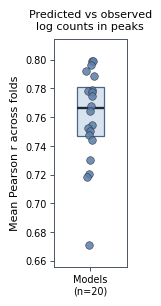

In [10]:
y = sample_summary["mean_pearson_r"].dropna().to_numpy(dtype=float)

rng = np.random.default_rng(1)
jitter = rng.normal(1, 0.045, len(y))
jitter = np.clip(jitter, 0.88, 1.12)

fig, ax = plt.subplots(figsize=(1.3, 3.0))

box_fill = "#D8E3F0"
box_edge = "#4B6584"
median_color = "#1F2937"
point_face = "#5E81AC"
point_edge = "#2E3440"

# IQR box + median; no whiskers.
ax.boxplot(
    y,
    positions=[1],
    widths=0.34,
    patch_artist=True,
    showfliers=False,
    boxprops=dict(
        facecolor=box_fill,
        edgecolor=box_edge,
        linewidth=0.9,
    ),
    medianprops=dict(
        color=median_color,
        linewidth=1.7,
    ),
    whiskerprops=dict(linewidth=0),
    capprops=dict(linewidth=0),
)

# Individual model values.
ax.scatter(
    jitter,
    y,
    s=30,
    facecolor=point_face,
    edgecolor=point_edge,
    linewidth=0.45,
    alpha=0.88,
    zorder=3,
)

ax.set_xlim(0.55, 1.45)
ax.set_xticks([1])
ax.set_xticklabels([f"Models\n(n={len(y)})"])
ax.set_ylabel("Mean Pearson r across folds", labelpad=4)
ax.set_title("Predicted vs observed\nlog counts in peaks", pad=7)

yrange = y.max() - y.min()
pad = max(0.01, 0.12 * yrange)
ax.set_ylim(y.min() - pad, y.max() + pad)

for spine in ax.spines.values():
    spine.set_linewidth(0.7)
    spine.set_color("#4B5563")

ax.tick_params(
    axis="both",
    length=3,
    width=0.7,
    color="#4B5563",
    pad=2,
)

fig.tight_layout(pad=0.6)

fig.savefig(
    OUTPUT_DIR / "chrombpnet_fig5b_left_panel.pdf",
    bbox_inches="tight",
)
fig.savefig(
    OUTPUT_DIR / "chrombpnet_fig5b_left_panel.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()


## 4. Figure 5b — representative ChromBPNet count-correlation scatter

This panel uses the scatter plot generated by ChromBPNet during model evaluation for the selected sample/fold.


In [13]:
scatter_png = (
    MODEL_ROOT
    / SCATTER_SAMPLE
    / SCATTER_FOLD
    / "evaluation"
    / "chrombpnet_only_peaks.counts_pearsonr.png"
)

if not scatter_png.exists():
    raise FileNotFoundError(
        "Representative scatter plot not found:\n"
        f"{scatter_png}\n\n"
        "Change SCATTER_SAMPLE and/or SCATTER_FOLD at the top of the notebook."
    )




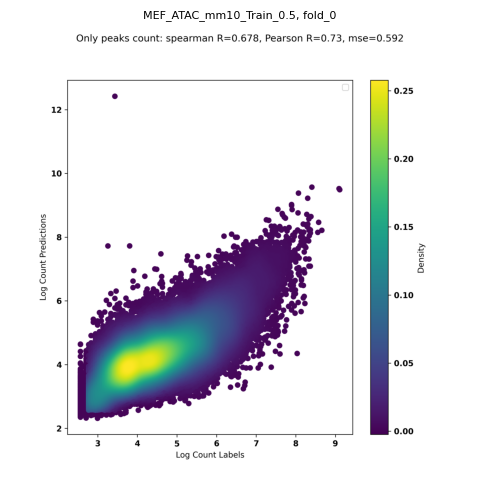

In [12]:
img = Image.open(scatter_png)

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(img)
ax.axis("off")
ax.set_title(f"{SCATTER_SAMPLE}, {SCATTER_FOLD}")

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "chrombpnet_fig5b_right_panel.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    OUTPUT_DIR / "chrombpnet_fig5b_right_panel.pdf",
    bbox_inches="tight",
)

plt.show()


## Outputs

After a successful run, `fig5b_outputs/` contains:

```text
chrombpnet_fold_level_pearson.tsv
chrombpnet_sample_mean_pearson.tsv
chrombpnet_fig5b_left_panel.pdf
chrombpnet_fig5b_left_panel.png
chrombpnet_fig5b_right_panel.pdf
chrombpnet_fig5b_right_panel.png
```

For the GitHub repository, the executed notebook can be retained **with outputs** so that the reported summary and Figure 5b result are visible without rerunning the analysis.
